# 7 · K-means

```{math}
\mu_j = \frac{1}{|C_j|}\sum_{i \in C_j} x_i
```

**Family:** distance-based · **Task:** clustering (unsupervised)

The only unsupervised algorithm in the video: three coloured clusters with an × at
each centre. Lloyd's algorithm alternates two steps until nothing changes:

1. **Assign** each point to its nearest centre, forming clusters $C_j$.
2. **Update** each centre to the mean of its cluster, $\mu_j$ above.

Each step can only lower the inertia $\sum_j \sum_{i\in C_j}\lVert x_i - \mu_j\rVert^2$,
so the loop always stops, though not necessarily at the best clustering.

## Imports

`ml8` is the book's own package; [The sample data](00_sample_data.ipynb) explains how it is
imported. This chapter uses:

| File | What this chapter uses |
|---|---|
| `ml8/data.py` | `data.blobs_data`: the three-blob sample |
| `ml8/scratch.py` | `scratch.inertia`: the k-means objective<br>`scratch.kmeans_lloyd`: Lloyd's k-means algorithm |
| `ml8/plotting.py` | the palette (`P.BLUE`, `P.FG`, `P.GREEN`, `P.PURPLE`, `P.RED`, `P.YELLOW`) |

In [1]:
# ml8 sits one folder above notebooks/, so put that folder on Python's search path
import sys
sys.path.insert(0, "..")

# Installed packages
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

# The book's own modules
from ml8 import data              # ml8/data.py: the seeded sample datasets
from ml8 import plotting as P     # ml8/plotting.py: colours and plot helpers
from ml8 import scratch           # ml8/scratch.py: the from-scratch formulas

P.use_style()  # the dark style used by every figure
pd.set_option("display.precision", 4)

converged after 3 updates


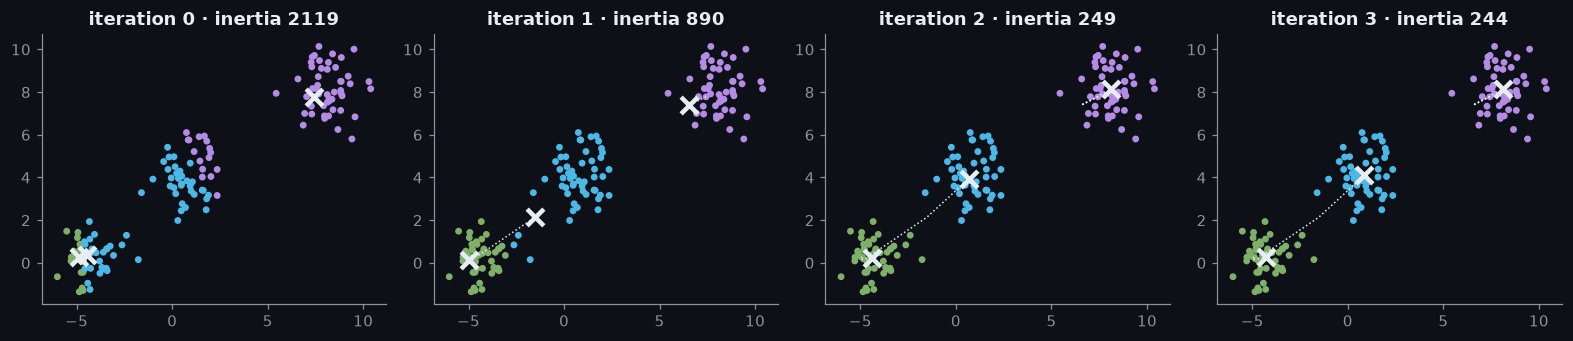

In [2]:
blobs = data.blobs_data()
X = blobs[["x1", "x2"]].to_numpy()
cents, assigns = scratch.kmeans_lloyd(X, k=3, seed=1)
print(f"converged after {len(cents) - 1} updates")

colors = np.array([P.BLUE, P.GREEN, P.PURPLE, P.RED, P.YELLOW])
fig, axes = plt.subplots(1, len(cents), figsize=(3.6 * len(cents), 3.2), squeeze=False)
for it, ax in enumerate(axes[0]):
    ax.scatter(X[:, 0], X[:, 1], s=12, c=colors[assigns[it]])
    trail = np.array(cents[: it + 1])
    for j in range(3):
        ax.plot(trail[:, j, 0], trail[:, j, 1], c=P.FG, lw=1, ls=":")
    ax.scatter(cents[it][:, 0], cents[it][:, 1], marker="x", s=120, c=P.FG, linewidths=3)
    ax.set_title(f"iteration {it} · inertia {scratch.inertia(X, cents[it], assigns[it]):.0f}")
plt.tight_layout()

## Check against scikit-learn

In [3]:
sk = KMeans(n_clusters=3, n_init=10, random_state=0).fit(X)
pd.DataFrame({"inertia": [scratch.inertia(X, cents[-1], assigns[-1]), sk.inertia_],
              "ARI vs true groups": [adjusted_rand_score(blobs.true_cluster, assigns[-1]), adjusted_rand_score(blobs.true_cluster, sk.labels_)]},
             index=["from scratch", "scikit-learn"])

,inertia,ARI vs true groups
from scratch,244.3686,1.0
scikit-learn,244.3686,1.0


The adjusted Rand index (ARI) compares a clustering with the true groups, ignoring how
clusters are numbered: 1 is a perfect match, around 0 is chance.

## Choosing k: the elbow

k,1,2,3,4,5,6,7,8
inertia,5689.9519,1276.4449,244.3686,206.6591,170.3158,178.2616,150.8245,135.4616
ARI,0.0000,0.5681,1.0000,0.8711,0.7404,0.8015,0.6362,0.6426


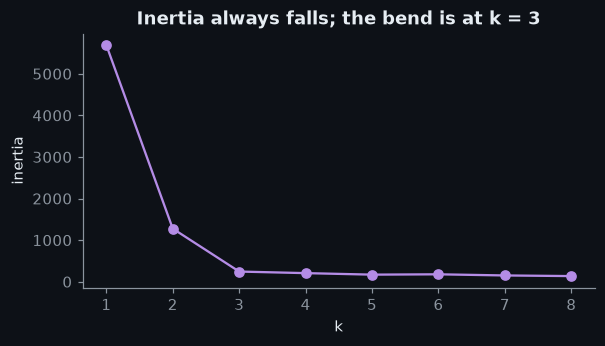

In [4]:
rows = []
for k in range(1, 9):
    c, a = scratch.kmeans_lloyd(X, k, seed=1)
    rows.append({"k": k, "inertia": scratch.inertia(X, c[-1], a[-1]), "ARI": adjusted_rand_score(blobs.true_cluster, a[-1])})
elbow = pd.DataFrame(rows).set_index("k")
ax = elbow.inertia.plot(marker="o", figsize=(6, 3), color=P.PURPLE)
ax.set_ylabel("inertia"); ax.set_title("Inertia always falls; the bend is at k = 3");
elbow.T

## Sensitivity to the starting centres

One random start can get stuck. That is why scikit-learn runs several starts
(`n_init`) with k-means++ seeding and keeps the best.

In [5]:
pd.Series({s: scratch.inertia(X, *(lambda c, a: (c[-1], a[-1]))(*scratch.kmeans_lloyd(X, 3, seed=s))) for s in range(10)},
          name="final inertia by seed").to_frame().T

,0,1,2,3,4,5,6,7,8,9
final inertia by seed,244.3686,244.3686,244.3686,244.3686,1238.9538,244.3686,244.3686,244.3686,1245.5447,1240.2869
